# Regresjonsanalyse
Søvnlengde, stressnivå, fysisk aktivitet og alder.

Vi undersøker hvor godt kan søvnlengde beskrives ved hjelp av stressnivå, fysisk aktivitetsnivå og alder. Først bruker vi enkel lineær regresjon med stressnivå som eneste forklaringsvariabel. Deretter bruker vi multippel lineær regresjon med flere forklaringsvariabler. 


### Enkel lineær regresjon:


Problemstillingen her er: Er det en lineær sammenheng mellom stressnivå og søvnlengde? Vi undersøker hypotesen om at personer med høyere stressnivå i gjennomsnitt har kortere søvnlengde.

Starter med å lese inn datasettet. 

Vi importerer biblioteket pandas, leser inn CSV-filen og lagrer den i en variabel, med navn df, som en tabell. 
head returnerer de 5 første radene fra datasettet. Dette gjør vi for å kontrollere at filen er lest inn riktig. 

In [34]:
import pandas as pd

df = pd.read_csv("Sleep_health_and_lifestyle_dataset.csv")

df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


Beskrivende statistikk. 

Før vi startet med regresjonsanalysen undersøkte vi de grunnleggende egenskaper ved datasettet. 
Med å bruke df.describe() får du en oppsumering av datasettet (som er i variablen df):

Datasettet har 374 observadsjoner for variablene. 
Gjennomsnitt søvnlengde er omtrent 7,13 timer, og den varierer fra 5,8 til 8,5 timer. 
Gjennomsnittlig stressnivå er omtrent 5,39, og varierer fra 3 til 8.

Det er fint å ha som bakgrunnsinformasjon, når vi skal blant annet tolke konstantleddet i regresjonsmodellen. 

In [35]:
df.describe()

,Person ID,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,187.500000,42.184492,7.132086,7.312834,59.171123,5.385027,70.165775,6816.844920
std,108.108742,8.673133,0.795657,1.196956,20.830804,1.774526,4.135676,1617.915679
min,1.000000,27.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000
25%,94.250000,35.250000,6.400000,6.000000,45.000000,4.000000,68.000000,5600.000000
50%,187.500000,43.000000,7.200000,7.000000,60.000000,5.000000,70.000000,7000.000000
75%,280.750000,50.000000,7.800000,8.000000,75.000000,7.000000,72.000000,8000.000000
max,374.000000,59.000000,8.500000,9.000000,90.000000,8.000000,86.000000,10000.000000


Spredningsdiagram. 


Før vi beregner regresjonslinjen, undersøker vi sammenhengen visuelt. I spredningsdiagrammet er stressnivå forklaringsvariabelen (x-aksen), mens søvnlengde er responsvariabelen (y-aksen). Hvert punkt viser registrert stressnivå og søvnlengde for en observasjon.
scatter er for å lage diagrammet. De under er for å legge til aksetitler. 

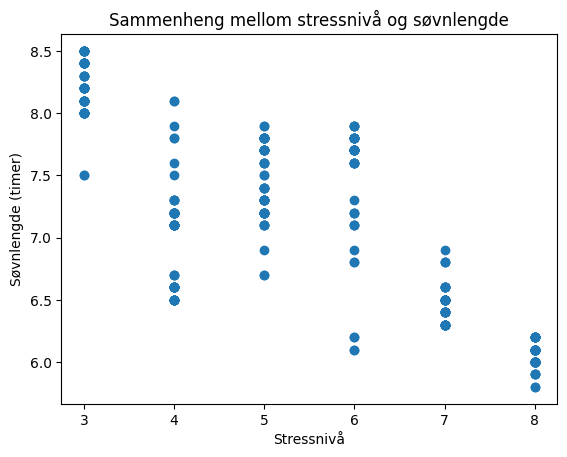

In [36]:
import matplotlib.pyplot as plt

plt.scatter(df["Stress Level"], df["Sleep Duration"])

plt.xlabel("Stressnivå")
plt.ylabel("Søvnlengde (timer)")
plt.title("Sammenheng mellom stressnivå og søvnlengde")

plt.show()

Diagrammet over viser at personer med høyere stressnivå generelt har kortere søvnlengde. Dette tyder på en negativ sammenheng mellom stressnivå og søvnlengde. Dette samsvarer med hypotesen H1: Personer med høyere stressnivå har i gjennomsnitt kortere søvnlengde. 

En del punkter i diagrammet ligger oppå hverandre, fordi flere observasjoner har de samme eller veldig like verdiene. Stressnivå er oppgitt som heltall, noe som bidrar til at punktene samles i vertikale grupper. Derfor viser ikke denne figuren nødvendigvis hvor mange observasjoner som ligger på hvert punkt. 

Vi kan ikke konkludere endelig bare fra dette diagrammet. Derfor går vi videre til enkel lineær regresjon.

Enkel lineær regresjon

Bruker statsmodels for å beregne en regresjonsmodell med minste kvadraters metode (OLS). Denne metoden gjør at vi finner den rette linjen som gir minst mulig samlet kvadrert avvik mellom observert og predikert søvnlengde. 



.ols angir regresjonsmodellen.
'Q("Sleep Duration") ~ Q("Stress Level")' betyr at søvnlengde forklares ved stressnivå. Bruker `Q(...)` fordi kolennenavnene inneholder mellomrom. 
.fit beregner modellen.
.summary viser de estimerte koeffisientene, p-verdier, R^2 og annen modellinformasjon. 

Regresjonen undersøker en statistisk sammenheng, ikke årsak og virkning. 

In [37]:
import statsmodels.formula.api as smf

modell1 = smf.ols(
    formula='Q("Sleep Duration") ~ Q("Stress Level")',
    data=df
).fit()

print(modell1.summary())

                             OLS Regression Results                            
Dep. Variable:     Q("Sleep Duration")   R-squared:                       0.658
Model:                             OLS   Adj. R-squared:                  0.657
Method:                  Least Squares   F-statistic:                     715.0
Date:                 Thu, 12 Nov 2026   Prob (F-statistic):           1.24e-88
Time:                         14:48:33   Log-Likelihood:                -244.18
No. Observations:                  374   AIC:                             492.4
Df Residuals:                      372   BIC:                             500.2
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             9.0903

Analysen over viser en tydelig negativ sammenheng mellom strssnivå og søvnlengde. 

9,0903 er konstantleddet. Modellens predikerte søvnlengde ved stressnivå 0. Datasettet har stressnivå 3-8, derfor tolker vi ikke dette som en realistisk prediksjon. 

-0,3636 er koeffisienten for stressnivå. Når stressnivået øker med en enhet, er den predikerte søvnlengden omtrent 0,364 timer kortere. Omtrent 22 minutter kortere søvn. 
Det betyr ikke at en faktisk økning i stress hos én person nødvendigvis gjør at personen sover 22 minutter mindre.

R^2 = 0,658 er forklaringsgrad. Betyr at 65,8% av varoasjonen i søvnlengde i datasettet forklares av den enkle lineære regresjonsmodellen med streessnivå. Det betyr ikke at modellen predikerer riktig i 65,8% av tilfellene. R^2 måler forklart variasjon, ikke treffiskkerhet i prosent.

P-verdien. P>|t| = 0,000 står for stressnivå. Betyr ikke at p-verdien er nøyaktig null. Den er bare så liten at python avrunder den. 
Derfor skriver vi: p<0,001. Dette gir statistisk støtte for at den lineære sammenhengen mellom stressnivå og søvnlengde er forskjellig fra null, gitt modellforutsetningene.  Sammen med det negative stigningstallet er dette i samsvar med hypotesen om at høyere stressnivå henger sammen med kortere søvn.

H1: Personer med høyere stressnivå har i gjennomsnitt kortere søvnlengde. Resultatene er i samsvar med H1. 
Både det negative stigningstallet og den lave p-verdien støtter en negativ sammenheng. 

Vi undersøker deretter residualene for å vurdere om modellen virker rimelig.

Undersøke residualene med TA plott. 

Et residual er forskjellen mellom den observerte søvnlengden og søvnlengden som modellen predikerer. 


modell1.fittedvalues inneholder modellens predikerte verdier, og modell1.resid inneholder residualene.

Vi lager et TA-plott med predikerte verdier på x-aksen og residualer på y-aksen. Den røde linjen markerer residual 0. Et slikt plott brukes til å se etter mønstre og om residualenes spredning virker omtrent lik langs x-aksen.

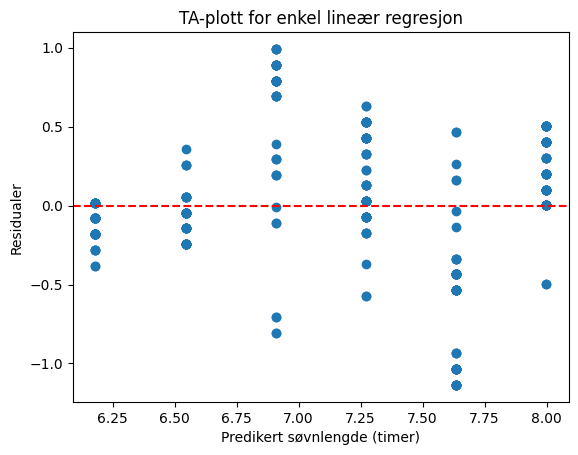

In [38]:
# Predikerte verdier og residualer fra modell 1
predikert = modell1.fittedvalues
residualer = modell1.resid

# TA-plott
plt.scatter(predikert, residualer)

plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predikert søvnlengde (timer)")
plt.ylabel("Residualer")
plt.title("TA-plott for enkel lineær regresjon")

plt.show()

Tolkning av TA plottet. 

Residualene ønskes å være sentrert rundt null, uten noe tydelig mønster. 
I plottet ligger residualene både over og under null. Det er en viss struktur i punktene. Spredningen varierer noe. 
Dette betyr ikke at vi ikke uten videre kan si at alle forutsetningene for lineær regresjon er oppfylt. 

Punktene ligger i lodrette grupper. Dette skyldes at stressnivået i datasetter bare har verdiene 3, 4, 5, 6, 7, og 8.
Alle personer med samme stressnivå får samme predikerte søvnlengde i den enkle modellen. Derfor havner redidualene på seks forskjellige x-verdier. 

Undersøker residualene med KK plott. 

Et KK plott hjelper pss å undersøke om residualene er tilnærmet normalfordelte. Vi sammenligner residualene med den rette referanselinjen. Dersom residualfordelingen ligger nær en normalfordeling, vil punktene vanligvis følge linjen ganske godt.

sm.qqplot(modell1.resid, line="s") lager et slikt plott for residualene fra modell 1.

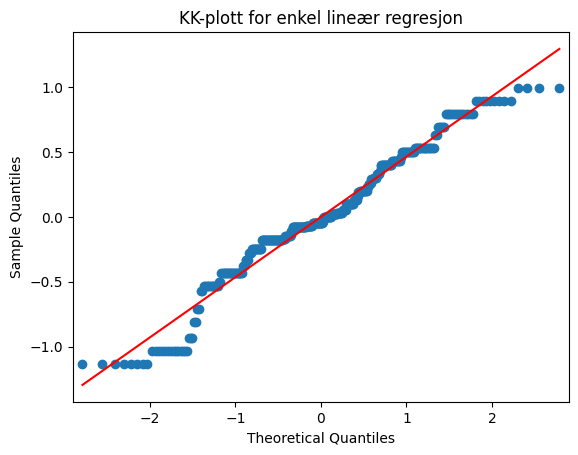

In [39]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

sm.qqplot(modell1.resid, line="s")

plt.title("KK-plott for enkel lineær regresjon")
plt.show()

KK-plottet brukes for å undersøke om residualene er tilnærmet normalfordelte. Dersom residualene er normalfordelte, forventer vi at punktene ligger omtrent langs den rette referanselinjen.

I vårt KK-plott ligger punktene forholdsvis nær linjen i midten, men det er avvik i begge ytterkantene. Vi ser også et trappetrinnslignende mønster, som kan skyldes at flere observasjoner har like residualverdier.

Dette kan tyde på at residualene ikke er helt normalfordelte. Normalfordelingsantakelsen ser derfor ikke ut til å være fullt oppfylt, og resultatene fra regresjonsmodellen bør tolkes med noe forsiktighet.

### Multippel lineær regresjon:

I den enkle regresjonen så vi bare på stressnivå. Nå undersøker vi om stressnivå, fysisk aktivitetsnivå, og alder samlet kan bidra til å forklare variasjonen i søvnlengde.

Vi bruker multippel lineær regresjon fordi den lar oss vurdere sammenhengen mellom søvnlengde og en forklaringsvariabel mens de andre forklaringsvariablene holdes konstante. Vi vil også sammenligne denne modellen med den enkle regresjonsmodellen.

Tilpasser den multipple regresjonsmodellen. 

I modellen er søvnlengde responsvariabelen (y), og stressnivå, fysisk aktivitetsnivå, og alder er forklaringsvariabler (x1, x2, og x3).

Vi undersøker om stressnivå, fysisk aktivitetsnivå og alder kan forklare variasjon i søvnlengde. Her er x1 stressnivå, x2 fysisk aktivitetsnivå og x3 alder. 
Vi bruker smf.ols() og .fit() igjen, for å tilpasse modellen til de samme 374 observasjonene. Et plusstegn i formelen mellom variablene betyr at de inngår samtidig i modellen.

In [40]:
import statsmodels.formula.api as smf

modell2 = smf.ols(
    formula='Q("Sleep Duration") ~ Q("Stress Level") + Q("Physical Activity Level") + Age',
    data=df
).fit()

print(modell2.summary())

                             OLS Regression Results                            
Dep. Variable:     Q("Sleep Duration")   R-squared:                       0.693
Model:                             OLS   Adj. R-squared:                  0.690
Method:                  Least Squares   F-statistic:                     278.3
Date:                 Thu, 12 Nov 2026   Prob (F-statistic):           1.79e-94
Time:                         14:48:35   Log-Likelihood:                -223.92
No. Observations:                  374   AIC:                             455.8
Df Residuals:                      370   BIC:                             471.5
Df Model:                            3                                         
Covariance Type:             nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Interc

Tolkning av den multipple regresjonen.

x_1 er stressnivå, x_2 er fysisk aktivitet, og x_3 er alder.

8,8173 er konstantledd. Dette er beregnet søvnlengde når alle tre forklaringsvariablene er 0. 

-0,3675 er stressnivå. Koeffisienten er negativ. Dette betyr at når stressnivået øker med en enhet, forventes søvnlengden å reduseres med omtrent 0,37 timer, når fysisk aktivitet og alder holdes konstant. 
P-verdien er mindre enn 0,05. Dermed er sammenhengen statistiks signifikant. 
Dette støtter vår hypotese om at høyere stressnivå henger sammen med kortere søvnlengde. 

0,0073 er fysisk aktivitet. Koeffisienten er positiv. Det betyr at når fysisk aktivitetsnivå øker med en enhet, forventes søvnlengden å øke med 0,0073 timer, når stressnivå og alder holdes konstant. 
P-verdien er mindre enn 0,05, så denne sammenhengen er også statistisk signifikant.
Dette støtter vår hypotese om at høyere fysisk aktivitetsnivå henger sammen emd lengre søvn.

−0,0033 er alder. Koeffisienten er svakt negativ. Det betyr at når alderen øker med ett år, forventes søvnlengden å reduseres med omtrent 0,0033 timer, når de andre variablene holdes konstant. 
Her er p-verdien 0,272, som er større enn 0,05. Det betyr at vi ikke har tilstrekkelig statistisk grunnlag for å konkludere med at alder har en sammenheng med søvnlengde når vi tar hensyn til stressnivå og fysisk aktivitet.


R^2 = 0,693. 69,3 % forklart variasjon. 
Adj. R^2 = 0,690. 69,0 % etter justering.
Dette betyr at modellen forklarer omtrent 69,3 % av variasjonen i søvnlengde i datasettet.
Vi fant tidligere at den enkle regresjonen hadde R^2 = 0,658

Den multiple modellen har altså en høyere forklaringsgrad. Men for å vurdere om det er nyttig å inkludere flere variabler, bør vi sammenligne justert R^2.

Sammenligner modellene med Adj. R^2

Vanlgi R^2 kan øke når vi legger til flere forklaringsvariabler, selv om de nye variablene ikke bidrar så mye. Derfor sammenligner vi også Adj. R^2 (justert R^2). Den tar hensyn til antallet forklaringsvariabler i forhold til antallet observasjoner. 

Koden under skriver ut justert R^2 fra både den enkle og den multiple modellen.

In [41]:
print("Modell 1 - Enkel regresjon")
print("Justert R²:", modell1.rsquared_adj)

print()

print("Modell 2 - Multippel regresjon")
print("Justert R²:", modell2.rsquared_adj)

Modell 1 - Enkel regresjon
Justert R²: 0.6568383473437086

Modell 2 - Multippel regresjon
Justert R²: 0.6904181164844854


Tolkning av sammenligningen. 

Justert R^2 øker fra omtrent 65,7% for enkel regresjon til 69,0% for multippel regresjon. Dette tyder på at den multiple modellen gir en bedre tilpasning til datasettet, selv når vi tar hensyn til at den har flere forklaringsvariabler.

Til diskusjon: Alder har en p-verdi på 0,272 og er ikke statistisk signifikant. Det betyr at vi ikke har funnet tydelig evidens for at alder bidrar med en lineær sammenheng når stress og fysisk aktivitet allerede er inkludert. Vi beholder likevel alder i modellen, siden vi valgte variabelen på forhånd og formulerte en hypotese om den.

TA-plott for multippel regresjon

Vi undersøker residualene her slik som vi gjorde for den enkle modellen. 
Vi bruker modell2.fittedvalues for de predikerte søvnlengdene og modell2.resid for avvikene mellom observert og predikert søvnlengde.

TA-plottet brukes til å vurdere om residualene ligger omtrent tilfeldig rundt null, og om spredningen er nokså jevn langs x-aksen.

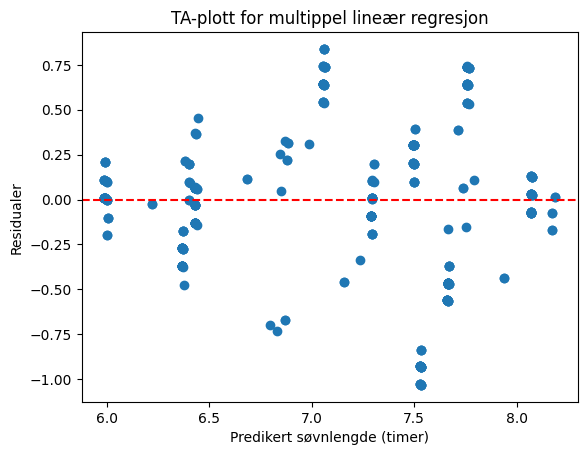

In [42]:
# Predikerte verdier og residualer fra modell 2
predikert2 = modell2.fittedvalues
residualer2 = modell2.resid

# TA-plott
plt.scatter(predikert2, residualer2)

plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predikert søvnlengde (timer)")
plt.ylabel("Residualer")
plt.title("TA-plott for multippel lineær regresjon")

plt.show()

Tolkning av TA plottet for multippel regresjon.

Residualene ligger på begge sider av null. Dette er positivt. Vi ser både positive og negative residualer, så modellen både overestimerer og underestimerer søvnlengden.

Punktene er samlet i vertikale grupper. Dette er spesielt tydelig rundt predikert søvnlengde på 6,0, 6,4, 7,1 og 7,8 timer.
Det kan skyldes at flere observasjoner har like eller svært like verdier for forklaringsvariablene. Vi vet allerede at datasettet inneholder mange identiske dataprofiler.

Spredningen varierer noe. Rundt en predikert søvnlengde på 7,5 timer ligger residualene fra omtrent −1 til +0,4, mens spredningen er mindre rundt 6,0 timer. Dette kan tyde på at antakelsen om konstant varians ikke er helt oppfylt.

KK plott for multippel regresjon

Nå skal vi undersøke om residualene ser ut til å være tilnærmet normalfordelte. Vi vurderer hvor godt punktene følger referanselinjen, og om det finnes tydelige avvik i endene.

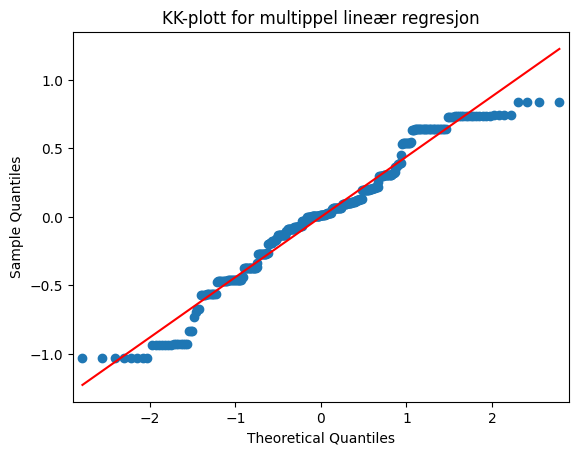

In [ ]:
import statsmodels.api as sm

sm.qqplot(modell2.resid, line="s")

plt.title("KK-plott for multippel lineær regresjon")
plt.show()


Tolkning av KK plottet for multippel regresjon.

KK-plottet viser at residualene ligger forholdsvis nær referanselinjen i midten, men at det er tydelige avvik i ytterkantene, spesielt på høyre side. Punktene danner også et trappetrinnslignende mønster, noe som kan skyldes at flere observasjoner har like residualverdier.

Dette tyder på at normalfordelingsantakelsen ikke er helt oppfylt. Resultatene fra regresjonsmodellen, spesielt p-verdiene og konfidensintervallene, bør derfor tolkes med forsiktighet.

Konklusjon:

Problemstilling: Hvor godt kan søvnlengde predikeres ved hjelp av stressnivå, fysisk aktivitetsnivå og alder?

Regresjonsanalysene viser at stressnivå har en tydelig negativ sammenheng med søvnlengde, mens fysisk aktivitet har en positiv sammenheng. Begge sammenhengene er statistisk signifikante. Alder hadde derimot ingen statistisk signifikant sammenheng med søvnlengde når de andre variablene ble holdt konstante.

Den multipple regresjonsmodellen forklarer 69,3% av variasjonen i søvnlengde, sammenlignet med 65,8% for den enkle modellen. Justert R^2 økte fra omtrent 0,657 til 0,690. Dette tyder på at den multiple modellen gir en noe bedre tilpasning til datasettet, også når vi tar hensyn til antall forklaringsvariabler.

TA-plottet og KK-plottet viste imidlertid enkelte avvik fra modellforutsetningene, blant annet variasjon i residualenes spredning og avvik fra normalfordelingen. Resultatene, særlig p-verdiene, bør derfor tolkes med forsiktighet.

Samlet sett tyder analysen på at stressnivå og fysisk aktivitet kan bidra til å forklare variasjonen i søvnlengde. Den multiple modellen gir en bedre tilpasning enn den enkle modellen, men avvikene fra modellforutsetningene gjør at vi må være forsiktige med konklusjonene.